## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

# 1. Read data (Now it is the same data)

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/groups_retrain_single_allele_balanced_data/" #!CHANGE
APPROACH = "DECOY_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
ALLELES = [
    'HLA-A*01:01',
    'HLA-A*03:01',
    # 'HLA-A*02:01б'
   'HLA-DRB1*01:01'
          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-DRB1*01:01']

## 2.0 Merge alleles together

In [4]:
# combination_size = len(ALLELES)
ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'])
# ALLELES = sorted([ 'HLA-A*03:01'])

ALLELES = sorted(['HLA-DRB1*01:01'])


combination_size = 1
TOTAL_SPLITS = 1
TARGET_LENGTHS= [10, 11, 12,13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]
RUNS = 5
USE_WEIGHTS = True

# SELECTED_RUN = 0
# SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
SELECTED_RUN = {0,1}

# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
models_to_read = ['bw']

In [5]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DRB1*01:01
Length 8: HLA-DRB1*01:01 - 39 
Length 9: HLA-DRB1*01:01 - 113 
Length 10: HLA-DRB1*01:01 - 123 
Length 11: HLA-DRB1*01:01 - 175 
Length 12: HLA-DRB1*01:01 - 368 
Length 13: HLA-DRB1*01:01 - 826 
Length 14: HLA-DRB1*01:01 - 1184 
Length 15: HLA-DRB1*01:01 - 6886 
Length 16: HLA-DRB1*01:01 - 1413 
Length 17: HLA-DRB1*01:01 - 984 
Length 18: HLA-DRB1*01:01 - 708 
Length 19: HLA-DRB1*01:01 - 316 
Length 20: HLA-DRB1*01:01 - 505 
Length 21: HLA-DRB1*01:01 - 177 
Length 22: HLA-DRB1*01:01 - 80 
Length 23: HLA-DRB1*01:01 - 57 
Length 24: HLA-DRB1*01:01 - 67 
Length 25: HLA-DRB1*01:01 - 50 
Length 26: HLA-DRB1*01:01 - 15 
Length 27: HLA-DRB1*01:01 - 12 
Length 28: HLA-DRB1*01:01 - 8 
Length 30: HLA-DRB1*01:01 - 7 


## Calculate weights for data

In [6]:
TARGET_LENGTHS

[10, 11, 12, 13, 14, 15, 16, 17, 18]

In [7]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [8]:
per_allele_per_kfold_per_length_weights = \
    calculate_weights_based_on_length_counts(count_df_train,
                                             selected_alleles=ALLELES,
                                             total_splits=TOTAL_SPLITS,
                                             selected_lengths=TARGET_LENGTHS,
                                             use_weights=USE_WEIGHTS)

Total data length for split 0 is 12667
Weights for lentgh 10 are {'HLA-DRB1*01:01': 102.98373983739837}
Weights for lentgh 11 are {'HLA-DRB1*01:01': 72.38285714285715}
Weights for lentgh 12 are {'HLA-DRB1*01:01': 34.421195652173914}
Weights for lentgh 13 are {'HLA-DRB1*01:01': 15.335351089588377}
Weights for lentgh 14 are {'HLA-DRB1*01:01': 10.69847972972973}
Weights for lentgh 15 are {'HLA-DRB1*01:01': 1.83952948010456}
Weights for lentgh 16 are {'HLA-DRB1*01:01': 8.964614295824488}
Weights for lentgh 17 are {'HLA-DRB1*01:01': 12.872967479674797}
Weights for lentgh 18 are {'HLA-DRB1*01:01': 17.891242937853107}


In [9]:
count_df_train

cnt
allele         split length      
HLA-DRB1*01:01 0     8         39
                     9        113
                     10       123
                     11       175
                     12       368
                     13       826
                     14      1184
                     15      6886
                     16      1413
                     17       984
                     18       708
                     19       316
                     20       505
                     21       177
                     22        80
                     23        57
                     24        67
                     25        50
                     26        15
                     27        12
                     28         8
                     30         7

# Read models

In [10]:
MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },

        "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 49,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },

    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01',
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },

    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [11]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['single_allele_imbalanced', 'single_allele_balanced', 'multiple_allele_balanced', 'single_allele_balanced_class2', 'single_allele_balanced_class2_biger', 'multiple_allele_imbalanced', 'multiple_allele_balanced_longer_training', 'mix_of_alleles', 'groups_retrain_single_allele_balanced_data'])

In [12]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
        "groups_retrain_single_allele_balanced_data"
    # 'multiple_allele_balanced_longer_training'
]


In [13]:
from hmm_logic_methods import load_model

In [14]:
import itertools
import mhcnames

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [15]:
list(per_name_binding_model.keys())

['0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0',
 '4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0']

## 2.2 Train
### 2.2.1 Define treshold

In [16]:
stop_threshold = 0
cutoff = 0.0005
per_symbol_portion = -4 / 9
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

4.697654320987655

In [17]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_model_total_df = dict()

for model_key, model in per_name_binding_model.items():
    per_state_information = dict()
    per_state_distribution = dict()
    per_level_information = defaultdict(float)

    for state in model.states:
        if state not in [model.start, model.end]:
            info_matrix = probs_to_info_matrix(state.distribution)
            per_state_distribution[state.name] = state.distribution.parameters[0]
            per_state_information[state.name] = sum(info_matrix.loc[0])
            # per_level_information[name_to_level[state.name]] += per_state_information[state.name]
    info_df = pd.DataFrame(per_state_information.items(), columns=["state", "info"])
    distr_df = pd.DataFrame(per_state_distribution.values())
    total_df = pd.concat([info_df, distr_df], axis=1)
    per_model_total_df[model_key] = total_df

In [18]:
filtered_dfs = list()

for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
    total_df = total_df.sort_values(by='info', ascending=False)
    total_df = total_df[total_df['info'] > 1.2]
    total_df['model'] = i
    total_df['model_name'] = model_key
    filtered_dfs.append(total_df)



In [19]:
filtered_dfs[0]

,state,info,A,C,D,E,F,G,H,I,...,P,Q,R,S,T,V,W,Y,model,model_name
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...


In [20]:
total_df = pd.concat(filtered_dfs)

In [21]:
total_df[total_df['model'] == 0]

,state,info,A,C,D,E,F,G,H,I,...,P,Q,R,S,T,V,W,Y,model,model_name
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...


In [22]:
values_to_run_pca_on = total_df.drop(columns=['state', 'info', 'model', 'model_name'])

In [23]:
values_to_run_pca_on

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
27,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,0.000080,0.001025,0.001799,0.009395,0.171099,0.003155,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439
29,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,0.000212,0.007819,0.000314,0.077943,0.004394,0.001339,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346
14,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,0.000076,0.108494,0.016394,0.000120,0.001008,0.000178,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210
25,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,0.000314,0.031942,0.001637,0.066315,0.156395,0.004475,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095
20,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,0.000083,0.438666,0.109198,0.010665,0.000037,0.069623,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402
38,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,0.000577,0.404053,0.027598,0.002137,0.014653,0.029949,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962
10,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,0.000421,0.242141,0.016629,0.000613,0.000497,0.008310,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371
28,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,0.002364,0.011702,0.002268,0.016258,0.017600,0.100528,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646
40,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,0.346873,0.129738,0.019605,0.000283,0.000973,0.017620,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088
17,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,0.000488,0.413889,0.024291,0.013238,0.000250,0.087229,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401


In [24]:
from sklearn.decomposition import PCA

# overwrite for non-linear test
def get_pca(df_concat, n_components=2, whiten=True):
    pca = PCA(n_components=n_components, whiten=whiten)
    X = df_concat.values
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

In [25]:
pca = get_pca(values_to_run_pca_on)

Shape (52, 20)
Explained variation per principal component: [0.34706406 0.1955399 ]


In [26]:
pca_result = pca.transform(values_to_run_pca_on.values)

In [27]:
total_df[['pca0', 'pca1']] = pca_result

In [28]:
total_df

,state,info,A,C,D,E,F,G,H,I,...,R,S,T,V,W,Y,model,model_name,pca0,pca1
27,s027,2.230645,0.169680,0.006188,0.006864,0.004960,0.000147,0.494215,0.000212,0.000146,...,0.000252,0.115751,0.013593,0.000945,0.000056,0.000439,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.592955,0.027389
29,s029,2.151597,0.499243,0.001742,0.002524,0.007309,0.001207,0.056968,0.001748,0.000942,...,0.001045,0.243621,0.063540,0.026669,0.000074,0.001346,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.460303,-0.416681
14,s014,2.140457,0.000105,0.000112,0.000045,0.000239,0.353283,0.000128,0.000129,0.076194,...,0.000382,0.000191,0.000163,0.028033,0.049517,0.365210,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.939126,2.113840
25,s025,1.871921,0.501401,0.004266,0.027336,0.002591,0.001484,0.084550,0.001666,0.006195,...,0.002230,0.004241,0.027074,0.074653,0.000140,0.001095,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,1.294711,-0.428126
20,s020,1.732298,0.079194,0.000200,0.000404,0.131886,0.005391,0.002008,0.001532,0.092575,...,0.000375,0.014595,0.002006,0.040954,0.000206,0.000402,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.979130,-1.300596
38,s038,1.592687,0.143505,0.009021,0.000252,0.013296,0.000655,0.106945,0.000097,0.047758,...,0.005612,0.001055,0.051190,0.140636,0.000050,0.000962,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.515607,-1.250732
10,s010,1.527813,0.000572,0.007860,0.000162,0.001194,0.110797,0.000305,0.005619,0.211057,...,0.005583,0.002089,0.000752,0.162837,0.149189,0.073371,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.924765,0.234386
28,s028,1.385195,0.005046,0.002801,0.013343,0.028448,0.058687,0.015308,0.041903,0.036687,...,0.120566,0.060673,0.438027,0.023555,0.000590,0.003646,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.218467,0.605204
40,s040,1.350485,0.168099,0.000131,0.000915,0.001366,0.027860,0.011310,0.031012,0.003554,...,0.059828,0.008644,0.064880,0.091234,0.000986,0.015088,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,0.137810,0.166010
17,s017,1.245946,0.053908,0.016439,0.003393,0.016522,0.084939,0.061396,0.018583,0.025028,...,0.002376,0.047260,0.079095,0.040618,0.000655,0.010401,0,0_run-10-11-12-13-14-15-16-17-18-45-st-baum-we...,-0.801975,-0.891005


In [29]:
from sklearn.cluster import KMeans

clustering = KMeans().fit(values_to_run_pca_on)
clustering.labels_

array([3, 4, 2, 4, 7, 1, 1, 5, 0, 7, 5, 4, 2, 2, 3, 4, 7, 7, 1, 1, 1, 2,
       0, 4, 7, 2, 3, 3, 4, 0, 2, 1, 3, 4, 7, 2, 2, 1, 7, 6, 0, 5, 4, 7,
       2, 3, 1, 0, 5, 0, 2, 0])

In [30]:
# from sklearn.cluster import MeanShift
#
# clustering = MeanShift(bandwidth=0.3).fit(values_to_run_pca_on)
# clustering.labels_

<AxesSubplot:xlabel='pca0', ylabel='pca1'>

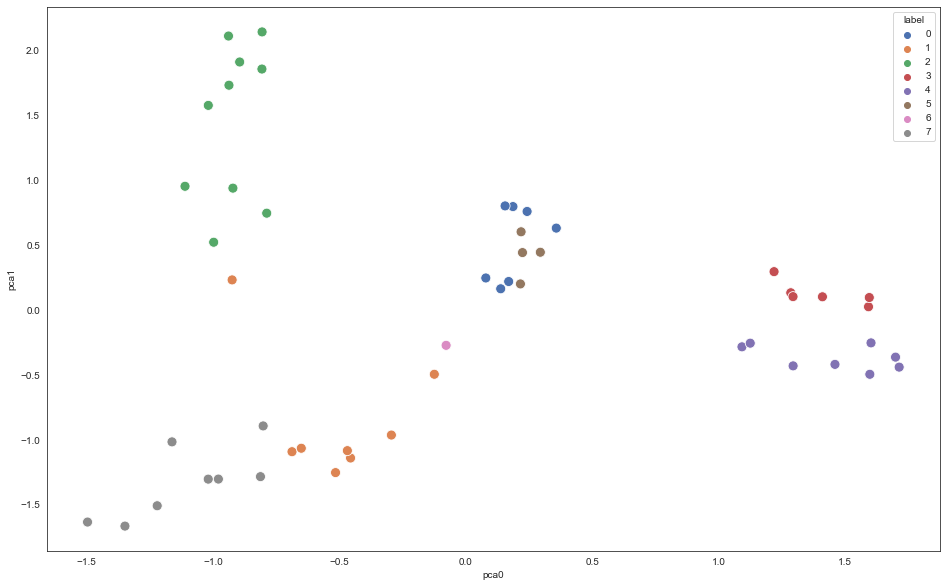

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
total_df['label'] = clustering.labels_
sns.scatterplot(data=total_df, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

In [32]:
temp_df= total_df.drop(columns=['pca0', 'pca1', 'model', 'info', 'state'])


In [33]:
labels_to_distr = temp_df.groupby('label').mean()

In [34]:
pd.DataFrame(labels_to_distr.loc[0]).T

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
0,0.102192,0.002902,0.021761,0.019462,0.026875,0.01429,0.031217,0.014741,0.355727,0.066716,0.009796,0.031552,0.006562,0.0239,0.106034,0.029063,0.021205,0.087271,0.011317,0.017416


In [35]:
clustering.labels_

array([3, 4, 2, 4, 7, 1, 1, 5, 0, 7, 5, 4, 2, 2, 3, 4, 7, 7, 1, 1, 1, 2,
       0, 4, 7, 2, 3, 3, 4, 0, 2, 1, 3, 4, 7, 2, 2, 1, 7, 6, 0, 5, 4, 7,
       2, 3, 1, 0, 5, 0, 2, 0])

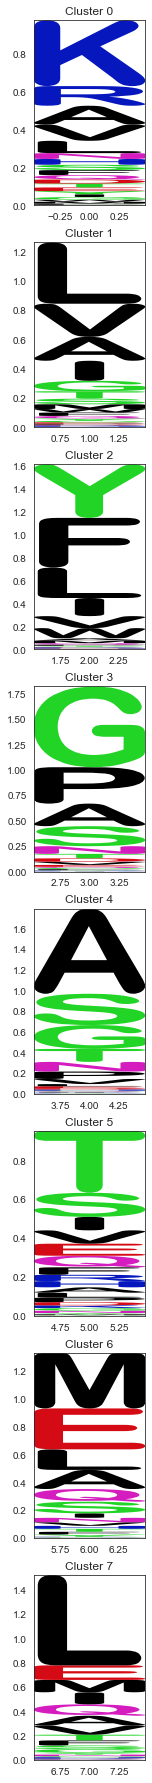

In [36]:
unique_labels = set(clustering.labels_)
fig, axes = plt.subplots(ncols=1, nrows=len(unique_labels), figsize=(2, len(unique_labels) * 4))

for label in unique_labels:
    # dummy_df = pd.DataFrame(columns = sorted(amino_acids), index = [0],  dtype=float)
    dummy_df = pd.DataFrame(labels_to_distr.loc[label]).T
    dummy_df.index.name = "pos"
    # for i, (acid, prob) in enumerate(state.distribution.parameters[0].items()):
    #     dummy_df.loc[0, acid] = prob

    # return dummy_df
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    ww_logo = logomaker.Logo(info_matrix,ax=axes[label],

                             font_name='Arial Rounded MT Bold',
                             #stack_order='small_on_top'
                             )
    ww_logo.ax.set_title(f"Cluster {label}")

In [37]:
per_state_number_group = {i: i // 5 for i in range(45)}
per_state_number_group

{0: 0,
 1: 0,
 2: 0,
 3: 0,
 4: 0,
 5: 1,
 6: 1,
 7: 1,
 8: 1,
 9: 1,
 10: 2,
 11: 2,
 12: 2,
 13: 2,
 14: 2,
 15: 3,
 16: 3,
 17: 3,
 18: 3,
 19: 3,
 20: 4,
 21: 4,
 22: 4,
 23: 4,
 24: 4,
 25: 5,
 26: 5,
 27: 5,
 28: 5,
 29: 5,
 30: 6,
 31: 6,
 32: 6,
 33: 6,
 34: 6,
 35: 7,
 36: 7,
 37: 7,
 38: 7,
 39: 7,
 40: 8,
 41: 8,
 42: 8,
 43: 8,
 44: 8}

In [38]:
per_label_most_confident_group = dict()
per_label_per_group_count = dict()
per_label_model_count = dict()
for label in unique_labels:
    groups = defaultdict(int)
    filtered_df = total_df[total_df['label'] == label]
    per_label_model_count[label] = len(filtered_df['model'].unique())
    for item in filtered_df.index.values:
        group_number = per_state_number_group[item]
        groups[group_number] += 1
        per_label_most_confident_group[label] = max(groups, key=groups.get)
    per_label_per_group_count[label] = dict(groups)
    print(f"label {label}:", dict(groups))

label 0: {8: 4, 5: 2, 4: 1}
label 1: {7: 5, 2: 1, 6: 1, 4: 1}
label 2: {2: 7, 1: 3}
label 3: {5: 6}
label 4: {5: 8}
label 5: {5: 3, 7: 1}
label 6: {4: 1}
label 7: {4: 5, 3: 2, 6: 1}


In [39]:
per_label_per_group_count

{0: {8: 4, 5: 2, 4: 1},
 1: {7: 5, 2: 1, 6: 1, 4: 1},
 2: {2: 7, 1: 3},
 3: {5: 6},
 4: {5: 8},
 5: {5: 3, 7: 1},
 6: {4: 1},
 7: {4: 5, 3: 2, 6: 1}}

In [40]:
per_label_most_confident_group

{0: 8, 1: 7, 2: 2, 3: 5, 4: 5, 5: 5, 6: 4, 7: 4}

In [41]:
per_label_model_count

{0: 5, 1: 5, 2: 5, 3: 5, 4: 5, 5: 3, 6: 1, 7: 5}

In [42]:
# if most model agreed to have this label -- select it

selected_labels_and_groups = {label:per_label_most_confident_group[label] for label,cnt in per_label_model_count.items() if cnt >= 3 and per_label_per_group_count[label][per_label_most_confident_group[label]] >= 5}

In [43]:
selected_labels_and_groups

{1: 7, 2: 2, 3: 5, 4: 5, 7: 4}

# Calculate viterbi path for each input peptide

In [264]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


In [265]:
joiner_positions = {i: [label for label, group in selected_labels_and_groups.items() if  group == original_position] for i,original_position in enumerate(sorted(set(selected_labels_and_groups.values())))}
joiner_positions

{0: [3], 1: [0], 2: [2, 4], 3: [6]}

In [266]:
per_model_anchors = dict()

max_labels = joiner_positions[max(joiner_positions.keys())]
min_labels = joiner_positions[min(joiner_positions.keys())]



                                    
# max_anchor_label = list(selected_labels_and_groups[max(selected_labels_and_groups.keys())])
# min_anchors_label = list(selected_labels_and_groups[max(selected_labels_and_groups.keys())])

    

In [267]:
for model_key in total_df['model_name'].unique():
    per_model_anchors[model_key] = dict()
    print("max labels were", max_labels)
    for label in max_labels:
        target_df = total_df[total_df['label'] == label]
        target_df = target_df[target_df['model_name'] == model_key]
        states = set(target_df['state'].values)
        per_model_anchors[model_key]['max'] = states
    print("mom labels were", min_labels)
    for label in min_labels:
        target_df = total_df[total_df['label'] == label]
        target_df = target_df[target_df['model_name'] == model_key]
        states = set(target_df['state'].values)
        per_model_anchors[model_key]['min'] = states
    

max labels were [6]
mom labels were [3]
max labels were [6]
mom labels were [3]
max labels were [6]
mom labels were [3]
max labels were [6]
mom labels were [3]
max labels were [6]
mom labels were [3]


In [268]:
per_model_anchors

{'0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s010',
   's017',
   's038'},
  'min': {'s014'}},
 '1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s017',
   's022',
   's033',
   's036'},
  'min': {'s009', 's011', 's014'}},
 '2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s035'},
  'min': {'s007', 's014'}},
 '3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s035'},
  'min': {'s012', 's013'}},
 '4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0': {'max': {'s039'},
  'min': {'s008', 's011'}}}

In [269]:
models = total_df['model_name'].unique()
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [270]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_binding_model.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides,
                                                                                   start_states=per_model_anchors[model_key]['min'],
                                                                                   end_states=per_model_anchors[model_key]['max'])
    result_df[f'core_start_{i}'] = viterbi_paths['core_start'].values
    result_df[f'core_end_{i}'] = viterbi_paths['core_end'].values
    result_df[f'v_prob_{i}'] = viterbi_paths['viterbi_probs'].values
    
    
    #find anchor for each model
    

Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s014'} and ends at {'s038', 's010', 's017'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15522.95it/s]


Model 1_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s009', 's014', 's011'} and ends at {'s033', 's022', 's017', 's036'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 16957.16it/s]


Model 2_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s014', 's007'} and ends at {'s035'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15447.67it/s]


Model 3_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s013', 's012'} and ends at {'s035'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14313.06it/s]


Model 4_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Core starts at {'s008', 's011'} and ends at {'s039'}
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 14264.73it/s]


In [271]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4
LGVLESDLPS,NaN,7.0,-34.252731,NaN,NaN,-33.219427,NaN,7.0,-35.495943,NaN,7.0,-32.689626,NaN,7.0,-35.421957
YSKTQKLGKS,NaN,7.0,-31.916392,NaN,NaN,-35.243204,NaN,7.0,-35.334662,NaN,NaN,-36.506492,NaN,7.0,-37.004006
LKAVPSQKRT,NaN,NaN,-35.991016,NaN,NaN,-34.879153,NaN,NaN,-34.051432,NaN,NaN,-35.860986,NaN,NaN,-35.134775
KRWIILGLNK,2.0,NaN,-35.371998,2.0,NaN,-34.994008,2.0,NaN,-34.353451,2.0,NaN,-34.181276,2.0,NaN,-36.968090
HAVSEGTKAV,NaN,8.0,-33.679166,NaN,NaN,-33.884455,1.0,8.0,-36.292271,NaN,NaN,-34.733541,1.0,8.0,-36.015337
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,4.0,11.0,-60.888998,4.0,12.0,-61.917285,4.0,11.0,-61.464062,4.0,11.0,-62.668933,4.0,12.0,-61.846632
AVPGKTFVSITPAEVGVL,6.0,15.0,-55.582025,6.0,9.0,-53.009603,6.0,15.0,-53.418387,6.0,16.0,-56.080425,6.0,14.0,-57.699439
VPHLRYLRLDGNYLKPPI,5.0,13.0,-57.824726,5.0,NaN,-58.745839,5.0,13.0,-58.661346,5.0,13.0,-59.686785,5.0,13.0,-55.566764
DIRRFDPIPAQYVRVYPE,4.0,NaN,-60.300122,4.0,14.0,-60.221567,4.0,12.0,-60.578339,4.0,14.0,-59.593768,4.0,12.0,-58.653598


In [286]:
result_df['len'] = result_df.index.str.len()

In [287]:
result_df[result_df['len']==15]

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
IVLSSELRLSHSRTH,6.0,NaN,-54.597379,6.0,9.0,-53.005587,6.0,13.0,-53.471242,6.0,NaN,-53.606437,6.0,NaN,-54.247664,15
MDNDLAATNDHNVME,4.0,7.0,-55.881695,NaN,12.0,-56.504279,4.0,NaN,-57.584505,4.0,NaN,-57.313575,4.0,12.0,-56.245541,15
EFHLDGEVLSLDKLK,7.0,13.0,-51.236767,7.0,NaN,-52.781992,7.0,13.0,-52.817318,7.0,13.0,-53.286024,1.0,13.0,-52.809613,15
SPSIVIALAGNKADL,NaN,12.0,-43.018359,4.0,12.0,-43.995721,4.0,NaN,-46.917426,4.0,NaN,-44.424954,4.0,12.0,-43.853973,15
ERSLWIIFSKNLNIK,3.0,11.0,-50.447994,3.0,13.0,-52.178278,3.0,13.0,-52.200601,4.0,NaN,-54.473978,3.0,11.0,-51.350411,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,3.0,NaN,-53.163595,4.0,NaN,-52.892626,4.0,NaN,-53.105015,NaN,NaN,-56.954938,4.0,NaN,-53.460928,15
ETQYSEMFGMVLAPA,3.0,11.0,-47.701542,3.0,NaN,-49.118373,3.0,11.0,-50.251743,3.0,NaN,-51.313428,3.0,11.0,-49.029525,15
FNMVYMPASWVMRIM,2.0,10.0,-59.870720,2.0,10.0,-61.548590,2.0,NaN,-58.216122,2.0,10.0,-61.358279,2.0,10.0,-59.141728,15
IFLSKDLQADIKGRD,NaN,12.0,-53.603963,6.0,NaN,-53.608143,NaN,12.0,-54.552659,NaN,NaN,-53.515098,NaN,12.0,-54.164187,15


In [289]:
'LALYQPANKHYIHCF'[2:12]

'LYQPANKHYI'

In [245]:
viterbi_paths['core_length'] = viterbi_paths['core_end'] + 1 - viterbi_paths['core_start']

In [246]:
viterbi_paths['core_length'].value_counts()

9.0     5817
10.0    1275
8.0      794
11.0     359
7.0      213
12.0     118
13.0      32
14.0       2
Name: core_length, dtype: int64

In [250]:
viterbi_paths[viterbi_paths['core_length'] == 12].iloc[1]['path']

'grouped_model-start>s002>s008>s011>s012>s018>s024>s021>s026>s028>s026>s033>s030>s039>s044>grouped_model-end'

# Construct model with joiners where joiners are selected

In [44]:
dict(sorted(selected_labels_and_groups.items(), key=lambda x:x[1]))

{2: 2, 7: 4, 3: 5, 4: 5, 1: 7}

In [45]:
set(selected_labels_and_groups.values())

{2, 4, 5, 7}

In [46]:
joiner_positions = {i: [label for label, group in selected_labels_and_groups.items() if  group == original_position] for i,original_position in enumerate(sorted(set(selected_labels_and_groups.values())))}
joiner_positions

{0: [2], 1: [7], 2: [3, 4], 3: [1]}

In [47]:
selected_labels_to_distr = labels_to_distr.loc[selected_labels_and_groups.keys()]

In [48]:

joiner_distributions = selected_labels_to_distr.to_dict(orient='index')


In [49]:
%load_ext autoreload
%autoreload 2

In [50]:

from hmm_logic_methods import init_simpliest_model_with_predefined_joiners_and_cycle

model = init_simpliest_model_with_predefined_joiners_and_cycle(joiner_parameters=joiner_distributions, freeze_distr=True)

grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, normalized to 1.0
grouped_model : s003 summed to 6.0, normalized to 1.0
grouped_model : s004 summed to 6.0, normalized to 1.0
grouped_model : s005 summed to 7.0, normalized to 1.0


In [51]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [52]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False)

in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...


In [53]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)
in validate_matrix(): Row sums in df are not close to 1. Reormalizing rows...


<class 'pyvis.network.Network'> |N|=8 |E|=43

## Prepare models for training

In [54]:
# Training params
algorithm = 'baum-welch'

params = dict()
params['states_per_group'] = [9, 5, 5, 5, 9]
if type(params['states_per_group']) == int:
    params['st'] = len(joiner_distributions) + params['states_per_group']*( len(joiner_positions)+1)
else:
    params['st'] = len(joiner_distributions) + sum(params['states_per_group'])
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 5
params['max_iters'] = 70
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 1
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0.25
params['distribution_inertia'] = 0



params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))

In [55]:
joiner_positions

{0: [2], 1: [7], 2: [3, 4], 3: [1]}

In [56]:
len(joiner_distributions)

5

In [57]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            init_simpliest_model_with_predefined_joiners_and_cycle
            prepared_model = init_simpliest_model_with_predefined_joiners_and_cycle(joiner_parameters=joiner_distributions, freeze_distr=True)
            # prepared_model = init_grouped_structure_model_with_predefined_joiners(joiner_positions, joiner_parameters=joiner_distributions, states_per_group=params['states_per_group'], freeze_distr=True)
            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, normalized to 1.0
grouped_model : s003 summed to 6.0, normalized to 1.0
grouped_model : s004 summed to 6.0, normalized to 1.0
grouped_model : s005 summed to 7.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, normalized to 1.0
grouped_model : s003 summed to 6.0, normalized to 1.0
grouped_model : s004 summed to 6.0, normalized to 1.0
grouped_model : s005 summed to 7.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, n

In [58]:
len(joiner_distributions)

5

In [59]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            init_simpliest_model_with_predefined_joiners_and_cycle
            prepared_model = init_simpliest_model_with_predefined_joiners_and_cycle(joiner_parameters=joiner_distributions, freeze_distr=True)
            # prepared_model = init_grouped_structure_model_with_predefined_joiners(joiner_positions, joiner_parameters=joiner_distributions, states_per_group=params['states_per_group'], freeze_distr=True)
            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, normalized to 1.0
grouped_model : s003 summed to 6.0, normalized to 1.0
grouped_model : s004 summed to 6.0, normalized to 1.0
grouped_model : s005 summed to 7.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, normalized to 1.0
grouped_model : s003 summed to 6.0, normalized to 1.0
grouped_model : s004 summed to 6.0, normalized to 1.0
grouped_model : s005 summed to 7.0, normalized to 1.0
grouped_model : grouped_model-start summed to 6.0, normalized to 1.0
grouped_model : s000 summed to 6.0, normalized to 1.0
grouped_model : s001 summed to 6.0, normalized to 1.0
grouped_model : s002 summed to 6.0, n

In [60]:
prepared_model.name

'4_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0'

# Do actual training

In [61]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model


In [62]:
TARGET_PATH_TO_RESULTS = TARGET_PATH_TO_RESULTS + "anchor_models/"

In [63]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'])
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)

run 0
split 0
train size 12667
Shuffling for fairness 
Simple training: Train Length 12667, init_batch_size None
[1] Improvement: -1069172.6495650387	Time (s): 2.626
[2] Improvement: 37655.91047175415	Time (s): 2.4
[3] Improvement: 10985.45374053903	Time (s): 1.966
[4] Improvement: 4405.621086034924	Time (s): 1.513
[5] Improvement: 2118.1093637188897	Time (s): 1.457
[6] Improvement: 1191.3268677676097	Time (s): 1.875
[7] Improvement: 760.9194434443489	Time (s): 1.972
[8] Improvement: 535.3654503878206	Time (s): 2.035
[9] Improvement: 403.75960747897625	Time (s): 1.732
[10] Improvement: 320.16835401393473	Time (s): 1.47
[11] Improvement: 263.79591281618923	Time (s): 1.681
[12] Improvement: 224.24292813334614	Time (s): 2.143
[13] Improvement: 195.77083824016154	Time (s): 1.712
[14] Improvement: 174.92809862550348	Time (s): 1.622
[15] Improvement: 159.49355253670365	Time (s): 1.502
[16] Improvement: 147.96623883396387	Time (s): 1.614
[17] Improvement: 139.296806499362	Time (s): 2.248
[18]

In [64]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
1
2
3
4
Wall time: 1.4 s


In [65]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False)
    print(i)

0
1
2
3
4
Wall time: 15.9 s


In [66]:
from hmm_visualization_methods import *
per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (1_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (2_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (3_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)
Converting graph for model (4_run-10-11-12-13-14-15-16-17-18-38-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0) (Delete zero edges)


In [67]:
TARGET_PATH_TO_RESULTS

'experiment_results/groups_retrain_single_allele_balanced_data/anchor_models/'

# Another approach to find anchors -- distribution distances

<AxesSubplot:>

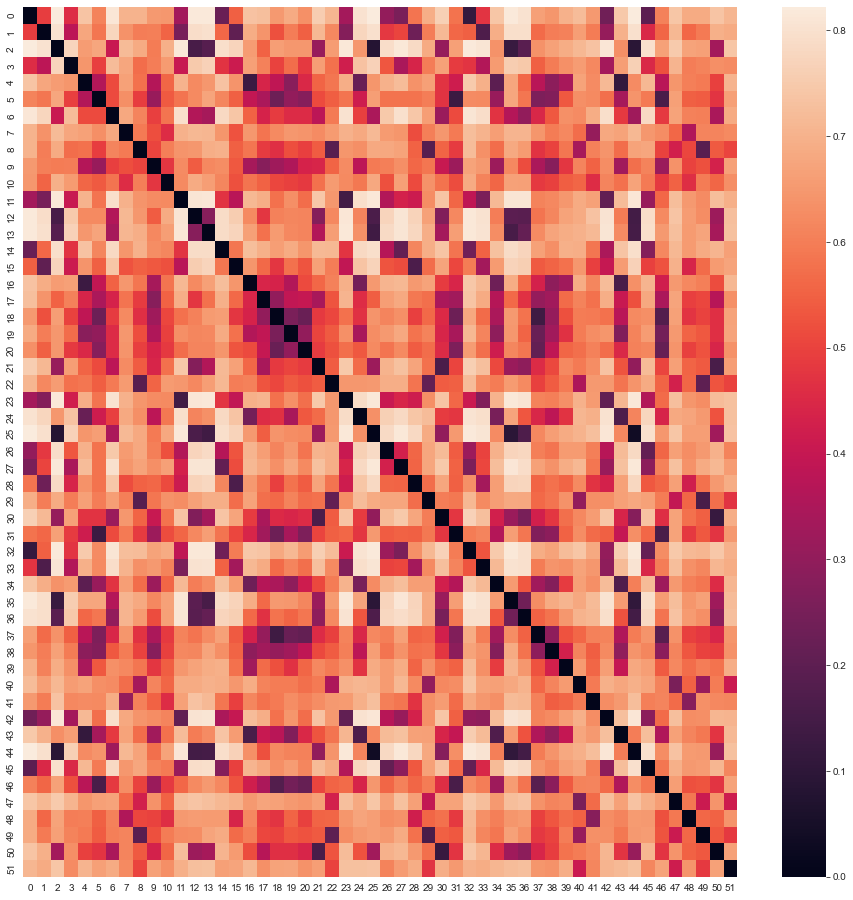

In [52]:
from scipy.special import rel_entr
from scipy.spatial.distance import pdist, squareform
dm = squareform(pdist(values_to_run_pca_on, lambda u, v: sum(rel_entr(u,v))))
dm = squareform(pdist(values_to_run_pca_on,metric='jensenshannon'))

fig, ax = plt.subplots(figsize=(16, 16))
sns.heatmap(dm)

In [372]:
df = pd.DataFrame(dm)
df['model'] = total_df['model'].values

In [373]:
lut = dict(zip(set(df['model']), sns.hls_palette(len(set(df['model'])), l=0.5, s=0.8)))

In [374]:
row_colors = df['model'].map(lut)

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:624: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


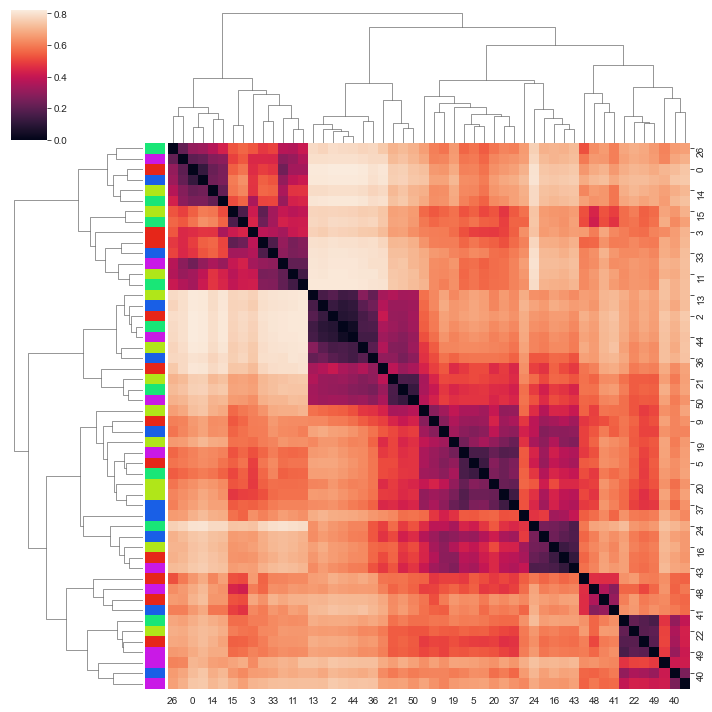

In [375]:

sns.clustermap(dm, row_colors=row_colors.to_numpy(), cmap='rocket')

## Calculate viterbi paths for train data (Try to find anchors)

In [49]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [51]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(model, allele_peptides)


Model 0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12667/12667 [00:01<00:00, 10292.21it/s]


Select unique paths...
	Unique paths: 11714


100%|██████████| 11714/11714 [00:00<00:00, 35700.07it/s]


In [52]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s001>s005>s014>s013>s015>s...,-10.002307,-0.714451,12,-34.795086,3
1,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.791529,-0.719435,13,-42.684984,1
2,grouped_model-start>s004>s009>s007>s005>s014>s...,-11.579876,-0.723742,14,-39.344564,1
3,grouped_model-start>s003>s007>s005>s014>s013>s...,-10.877871,-0.725191,13,-36.525293,2
4,grouped_model-start>s000>s001>s005>s014>s013>s...,-10.894956,-0.726330,13,-37.903886,1
...,...,...,...,...,...,...
11709,grouped_model-start>s000>s009>s012>s017>s023>s...,-27.080313,-1.592960,15,-53.481328,1
11710,grouped_model-start>s003>s008>s014>s011>s018>s...,-27.232899,-1.601935,15,-54.368034,1
11711,grouped_model-start>s002>s000>s002>s001>s006>s...,-27.282463,-1.604851,15,-59.117454,1
11712,grouped_model-start>s003>s004>s009>s007>s008>s...,-28.499659,-1.676451,15,-56.238231,1


In [66]:
state_names = [f"s{i:03d}".format(i) for i in range(len(model.states) - 2)] # minus start minus end

# allele_bw_paths_df.loc[:,state_names] = 0

per_state_counts = dict()

In [67]:
for state_name in state_names:
    per_state_counts[state_name] =  allele_bw_paths_df[allele_bw_paths_df['path'].str.contains(state_name)]['peptide_cnts'].sum()


In [68]:
per_state_counts

{'s000': 4215,
 's001': 4885,
 's002': 3780,
 's003': 2513,
 's004': 5635,
 's005': 6680,
 's006': 2045,
 's007': 6424,
 's008': 3834,
 's009': 3114,
 's010': 2078,
 's011': 2275,
 's012': 2398,
 's013': 8064,
 's014': 8126,
 's015': 6469,
 's016': 2003,
 's017': 1406,
 's018': 1941,
 's019': 2266,
 's020': 8900,
 's021': 5908,
 's022': 1625,
 's023': 3999,
 's024': 1478,
 's025': 722,
 's026': 1966,
 's027': 5314,
 's028': 2436,
 's029': 3851,
 's030': 7591,
 's031': 1568,
 's032': 6300,
 's033': 2569,
 's034': 3135,
 's035': 3362,
 's036': 4899,
 's037': 3494,
 's038': 8420,
 's039': 2492,
 's040': 5131,
 's041': 2712,
 's042': 5215,
 's043': 4777,
 's044': 7069}

In [69]:
import seaborn as sns

In [84]:
df = pd.DataFrame.from_dict(per_state_counts, orient='index', columns=['cnt'])

# sns.barplot(x=list(per_state_counts.keys()), y=list(per_state_counts.values()))

<AxesSubplot:>

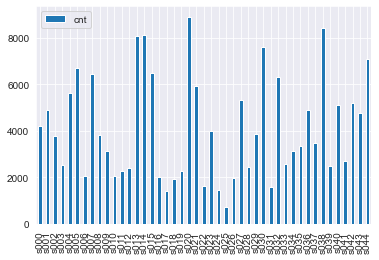

In [85]:
df.plot(kind='bar')

In [87]:
df.sort_values(by='cnt', ascending=False)

,cnt
s020,8900
s038,8420
s014,8126
s013,8064
s030,7591
s044,7069
s005,6680
s015,6469
s007,6424
s032,6300


In [88]:
model.dense_transition_matrix()

array([[0.        , 0.18783749, 0.24838837, ..., 0.        , 0.        ,
        0.        ],
       [0.02338106, 0.        , 0.08356533, ..., 0.        , 0.        ,
        0.        ],
       [0.10202855, 0.22541672, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.70792018],
       [0.24782062, 0.12390521, 0.03135931, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])